# 02 – FITS verstehen

**Was:** Eine i2d-Datei auseinandernehmen: Extensions, Header, Einheiten, Koordinatensystem (WCS), Histogramm und Dynamikumfang. Am Ende einmal kurz alle sechs Filter im Vergleich.

**Warum:** Bevor wir strecken und färben, müssen wir wissen, *was* in den Pixeln steht. Das entspricht dem Blick in die Metadaten einer `.czi`/`.lif`-Datei (Kanäle, Pixelgröße, Bittiefe, Laserleistung), bevor man in Fiji die Helligkeit anpasst.

**Beispieldatei:** F405N (Langwellenkanal, kleinere Datei). Das ist eine Schmalband-Emissionslinie (Wasserstoff, Brackett-α); dazu mehr in Etappe 5.

**Ergebnis:** Alle 6 i2d-Dateien lassen sich öffnen und sind intakt. Jede hat 10 Extensions; für Farbbilder brauchen wir SCI (Einheit MJy/sr). Kurzwellenbilder: ≈4900 × 4900 px bei 0,0307″/px; Langwellenbilder: ≈2350 × 2350 px bei 0,063″/px; Bildfeld jeweils ≈2,47′ × 2,47′. Etwa 2 % der Pixel sind NaN.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.stats import sigma_clipped_stats
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch, LinearStretch
import astropy.units as u

DATA_DIR = Path("..") / "data" / "ngc3132_nircam"
FILES = sorted(DATA_DIR.glob("*_i2d.fits"))
path = DATA_DIR / "jw02733-o001_t001_nircam_f405n-f444w_i2d.fits"
print(len(FILES), "files found; example:", path.name)

6 files found; example: jw02733-o001_t001_nircam_f405n-f444w_i2d.fits


## 1. Aufbau der Datei: Extensions

Eine FITS-Datei ist ein Stapel aus **HDUs** (Header-Data-Units): jede hat einen Text-Header und optional Daten. Wie ein Multi-Channel-TIFF, nur dass die „Kanäle“ hier unterschiedliche Bedeutung haben.

Soweit ich es aus der JWST-Dokumentation kenne (Details bitte bei Bedarf dort nachlesen):

| Extension | Inhalt | Mikroskopie-Analogie |
|---|---|---|
| PRIMARY | nur Header: Teleskop, Instrument, Filter, Belichtung | Datei-Metadaten |
| **SCI** | das Bild, in physikalischen Einheiten | der eigentliche Kanal |
| ERR | Unsicherheit pro Pixel | Fehlerbalken pro Pixel |
| CON | Kontext: welche Einzelbelichtungen zu einem Pixel beigetragen haben (Bitmaske) | welche Kacheln überlappen |
| WHT | Gewicht, grob ∝ effektive Belichtung pro Pixel | Überlappungs-/Belichtungskarte beim Stitching |
| VAR_POISSON / VAR_RNOISE / VAR_FLAT | Varianzanteile: Photonenrauschen, Ausleserauschen, Flatfield | Schrot- vs. Detektorrauschen |
| HDRTAB | Tabelle mit Header-Infos der Einzelbelichtungen | – |
| ASDF | eingebettete Metadaten im ASDF-Format (u. a. das vollständige Koordinatenmodell) | – |

Für Farbbilder brauchen wir praktisch nur **SCI** (und zur Kontrolle WHT).

In [2]:
fits.info(path)

Filename: ../data/ngc3132_nircam/jw02733-o001_t001_nircam_f405n-f444w_i2d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     282   ()      
  1  SCI           1 ImageHDU        75   (2356, 2348)   float32   
  2  ERR           1 ImageHDU        10   (2356, 2348)   float32   
  3  CON           1 ImageHDU        10   (2356, 2348, 1)   int32   
  4  WHT           1 ImageHDU         9   (2356, 2348)   float32   
  5  VAR_POISSON    1 ImageHDU         9   (2356, 2348)   float32   
  6  VAR_RNOISE    1 ImageHDU         9   (2356, 2348)   float32   
  7  VAR_FLAT      1 ImageHDU         9   (2356, 2348)   float32   
  8  HDRTAB        1 BinTableHDU    544   8R x 267C   [23A, 5A, 3A, 48A, 7A, 13A, 7A, 5A, 5A, 7A, 10A, 4A, L, D, D, 32A, 50A, 32A, 21A, 3A, 3A, 10A, 12A, 23A, 23A, 26A, 11A, 5A, 3A, 3A, 2A, 1A, 2A, 1A, L, 14A, 23A, 2A, 26A, 20A, 27A, 10A, K, L, L, L, L, 8A, 8A, 5A, D, D, D, D, D, D, 27A, D, D, 6A, 8A, 1A, 4A, 5A, K, 26A, 5A, L, 

## 2. Primärer Header: Was wurde wie aufgenommen?

Interessant sind `FILTER` und `PUPIL`: Bei den Schmalbandfiltern F405N/F470N sitzt der Schmalbandfilter im *Pupillenrad* und wird mit dem Breitbandfilter F444W im *Filterrad* kombiniert, deshalb tauchte in MAST `F444W;F405N` auf. Den Durchlassbereich bestimmt im Wesentlichen der schmale Filter, ähnlich wie ein Emissionsfilter hinter einem breiteren Sperrfilter.

In [3]:
h0 = fits.getheader(path, ext=0)
for key in ["TELESCOP", "INSTRUME", "CHANNEL", "FILTER", "PUPIL", "TARGPROP",
            "DATE-OBS", "EFFEXPTM", "CAL_VER", "CRDS_CTX"]:
    print(f"{key:<9} = {h0.get(key)!s:<25} / {h0.comments[key] if key in h0 else ''}")

TELESCOP  = JWST                      / Telescope used to acquire the data
INSTRUME  = NIRCAM                    / Instrument used to acquire the data
CHANNEL   = LONG                      / Instrument channel
FILTER    = F444W                     / Name of the filter element used
PUPIL     = F405N                     / Name of the pupil element used
TARGPROP  = NGC-3132                  / Proposer's name for the target
DATE-OBS  = 2022-06-03                / [yyyy-mm-dd] UTC date at start of exposure
EFFEXPTM  = 2319.144                  / [s] Effective exposure time
CAL_VER   = 3.0.0                     / Calibration Software Version
CRDS_CTX  = jwst_1584.pmap            / CRDS context (.pmap) used to select ref files


## 3. SCI-Header: Einheiten

`BUNIT` ist **MJy/sr**: *Flächenhelligkeit*, also Strahlungsfluss pro Raumwinkel (Megajansky pro Steradiant). Das sind keine Zählwerte wie Graustufen einer Kamera, sondern bereits kalibrierte physikalische Größen; die Pipeline hat die Detektorzählraten schon umgerechnet (`PHOTMJSR` ist der Umrechnungsfaktor).

Konsequenz: Werte sind Gleitkommazahlen, können leicht **negativ** sein (Rauschen um einen abgezogenen Hintergrund) und haben einen riesigen Dynamikumfang. `PIXAR_SR` / `PIXAR_A2` geben die Fläche eines Pixels am Himmel an.

In [5]:
h1 = fits.getheader(path, extname="SCI")
for key in ["BUNIT", "PHOTMJSR", "PIXAR_SR", "PIXAR_A2", "NAXIS1", "NAXIS2"]:
    print(f"{key:<9} = {h1.get(key)!s:<25} / {h1.comments[key] if key in h1 else ''}")

BUNIT     = MJy/sr                    / physical units of the array values
PHOTMJSR  = 9.571999549865723         / Flux density (MJy/steradian) producing 1 cps
PIXAR_SR  = 9.33688249964098e-14      / Nominal pixel area in steradians
PIXAR_A2  = 0.003972392559823891      / Nominal pixel area in arcsec^2
NAXIS1    = 2356                      / 
NAXIS2    = 2348                      / 


## 4. Daten laden: Form, Datentyp, NaN-Ränder

`memmap=True` liest nur, was gebraucht wird, nicht die ganze Datei auf einmal in den Speicher. Pixel ohne gültige Daten (außerhalb des Bildfelds, Lücken zwischen Detektoren) sind **NaN**, nicht 0. Das ist wichtig: Eine 0 würde Statistik und Streckung verfälschen.

In [6]:
with fits.open(path, memmap=True) as hdul:
    sci = hdul["SCI"].data.astype(np.float32)   # copy into memory so the file can close
    wht = hdul["WHT"].data.astype(np.float32)

finite = np.isfinite(sci)
print("shape:", sci.shape, "dtype:", sci.dtype)
print(f"NaN pixels: {100 * (~finite).mean():.1f} %")
print(f"negative pixels (of finite): {100 * (sci[finite] < 0).mean():.1f} %")

shape: (2348, 2356) dtype: float32
NaN pixels: 2.0 %
negative pixels (of finite): 3.9 %


## 5. Koordinatensystem (WCS)

Das **WCS** (World Coordinate System) übersetzt Pixel ↔ Himmelskoordinaten (Rektaszension/Deklination). Für die Mikroskopie wäre das eine Stage-Position plus Pixelgröße plus Drehwinkel in einem.

Zwei Dinge sind für später wichtig:
- **Pixelgröße**: unterscheidet sich zwischen Kurz- und Langwellenkanal (→ Etappe 3).
- **Drehung**: Das Bild ist nicht „Norden oben“ ausgerichtet (die `PC`-Matrix enthält eine Rotation). `reproject` erledigt das später automatisch.

In [7]:
wcs = WCS(h1)
scale = (proj_plane_pixel_scales(wcs) * u.deg).to(u.arcsec)
print("pixel scale:", np.round(scale, 4))

ny, nx = sci.shape
center = wcs.pixel_to_world(nx / 2, ny / 2)
print("image center:", center.to_string("hmsdms"))
print("field of view: {:.2f} x {:.2f} arcmin".format(*(np.array([nx, ny]) * scale.to(u.arcmin).value)))

pixel scale: [0.063 0.063] arcsec
image center: 10h07m01.77031886s -40d26m11.26434267s
field of view: 2.47 x 2.47 arcmin


Set DATE-AVG to '2022-06-03T16:26:05.326' from MJD-AVG.
Set DATE-END to '2022-06-03T16:50:25.519' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.665782 from OBSGEO-[XYZ].
Set OBSGEO-H to 1655836536.664 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


## 6. Erster Blick: linear vs. gestreckt

Linear (Minimum bis Maximum) sieht man fast nur den hellen Zentralstern, weil wenige sehr helle Pixel die Skala bestimmen. Mit Perzentil-Grenzen und einer asinh-Kurve wird der Nebel sichtbar. Das ist die gleiche Idee wie in Fiji *Brightness/Contrast* mit „Auto“ plus eine nichtlineare LUT.

**Nur Vorschau**: die eigentliche Wahl der Streckung treffen und begründen wir in Etappe 4. Achsen in Himmelskoordinaten dank `projection=wcs`.

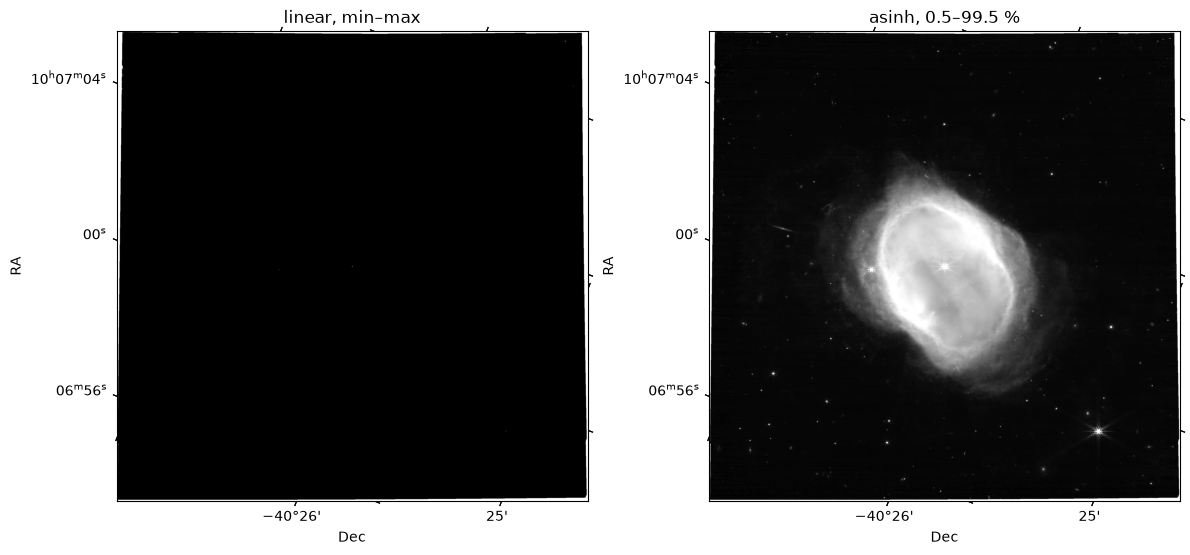

In [8]:
fig = plt.figure(figsize=(12, 6))
norms = {
    "linear, min–max": ImageNormalize(sci, vmin=np.nanmin(sci), vmax=np.nanmax(sci), stretch=LinearStretch()),
    "asinh, 0.5–99.5 %": ImageNormalize(sci, interval=PercentileInterval(99), stretch=AsinhStretch()),
}
for i, (title, norm) in enumerate(norms.items(), start=1):
    ax = fig.add_subplot(1, 2, i, projection=wcs)
    ax.imshow(sci, origin="lower", cmap="gray", norm=norm)
    ax.set_title(title)
    ax.coords[0].set_axislabel("RA")
    ax.coords[1].set_axislabel("Dec")
plt.tight_layout()

## 7. Histogramm und Hintergrund

Das Histogramm (logarithmische y-Achse) zeigt den typischen Aufbau astronomischer Bilder: ein schmaler, hoher Peak um den Hintergrund nahe 0 und ein sehr langer Schwanz zu hellen Werten (Nebel, Sterne).

`sigma_clipped_stats` schätzt Hintergrund und Rauschen robust: Es verwirft iterativ alles, was mehr als 3σ abweicht (Sterne, Nebel), und rechnet mit dem Rest. Das ähnelt der Hintergrundbestimmung in einer ROI ohne Zellen, nur automatisch.

background (sigma-clipped): median = 0.1531, std = 0.1925 MJy/sr
     0.5 % percentile:     -0.116
      50 % percentile:      0.173
      99 % percentile:     24.297
    99.9 % percentile:     33.965
   99.99 % percentile:     87.755
  max:    27005.9  ->  dynamic range max/std ≈ 140,298


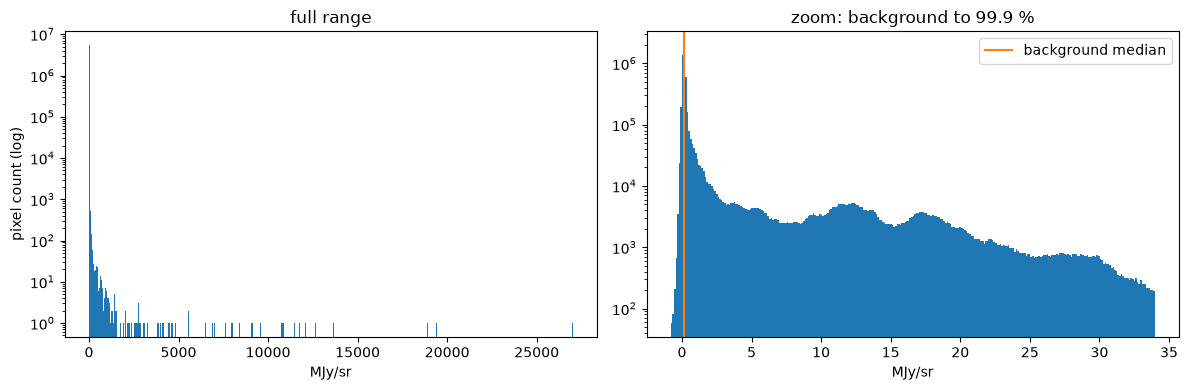

In [9]:
vals = sci[finite]
mean, median, std = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)
pcts = np.percentile(vals, [0.5, 50, 99, 99.9, 99.99])
print(f"background (sigma-clipped): median = {median:.4f}, std = {std:.4f} MJy/sr")
for p, v in zip([0.5, 50, 99, 99.9, 99.99], pcts):
    print(f"  {p:>6} % percentile: {v:10.3f}")
print(f"  max: {vals.max():10.1f}  ->  dynamic range max/std ≈ {vals.max() / std:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(vals, bins=500, log=True)
axes[0].set(title="full range", xlabel="MJy/sr", ylabel="pixel count (log)")
lo, hi = median - 5 * std, pcts[3]
axes[1].hist(vals[(vals > lo) & (vals < hi)], bins=300, log=True)
axes[1].axvline(median, color="C1", label="background median")
axes[1].set(title="zoom: background to 99.9 %", xlabel="MJy/sr")
axes[1].legend()
plt.tight_layout()

## 8. Gewichtskarte (WHT): Wo ist das Bild wie gut belichtet?

Das i2d-Bild ist aus mehreren versetzten Einzelbelichtungen (Dithers) und Detektoren zusammengesetzt. WHT zeigt, wo viele oder wenige Aufnahmen beitragen. Ränder und Detektorlücken haben weniger Gewicht und rauschen stärker. Das entspricht der Überlappungskarte beim Kachel-Stitching.

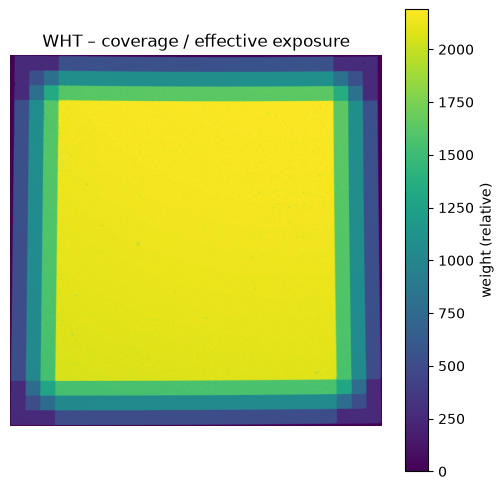

In [10]:
plt.figure(figsize=(6, 6))
plt.imshow(wht, origin="lower", cmap="viridis")
plt.colorbar(label="weight (relative)")
plt.title("WHT – coverage / effective exposure")
plt.axis("off");

## 9. Alle sechs Filter im Überblick (und Integritätscheck)

Öffnet jede Datei, liest die wichtigsten Header-Werte und eine Kurzstatistik. Wenn eine Datei beim Download beschädigt worden wäre, würde es hier einen Fehler geben. Die Kurzwellenbilder brauchen jeweils ≈100 MB RAM, das ist unkritisch.

Sortiert nach Wellenlänge (die Zahl im Filternamen ist die Wellenlänge in 1/100 µm: F090W ≈ 0,9 µm, F470N ≈ 4,7 µm).

In [11]:
rows = []
for f in FILES:
    with fits.open(f, memmap=True) as hdul:
        p, s = hdul[0].header, hdul["SCI"].header
        data = hdul["SCI"].data
        fin = np.isfinite(data)
        _, med, sd = sigma_clipped_stats(data[fin], sigma=3.0, maxiters=5)
        pix = (proj_plane_pixel_scales(WCS(s)) * u.deg).to(u.arcsec).value[0]
        band = p["PUPIL"] if p["PUPIL"] != "CLEAR" else p["FILTER"]
        rows.append((band, p["FILTER"], p["PUPIL"], p["CHANNEL"], data.shape, pix,
                     s["BUNIT"], p["EFFEXPTM"], 100 * (~fin).mean(), med, sd,
                     np.percentile(data[fin], 99.9)))

rows.sort(key=lambda r: int(r[0][1:4]))
print(f"{'band':<6}{'FILTER':<7}{'PUPIL':<7}{'chan':<6}{'shape':<14}{'pix_as':>7}"
      f"{'unit':>8}{'t_exp':>8}{'NaN%':>6}{'bkg':>8}{'noise':>8}{'p99.9':>8}")
for r in rows:
    print(f"{r[0]:<6}{r[1]:<7}{r[2]:<7}{r[3]:<6}{str(r[4]):<14}{r[5]:7.4f}"
          f"{r[6]:>8}{r[7]:8.0f}{r[8]:6.1f}{r[9]:8.3f}{r[10]:8.3f}{r[11]:8.1f}")

Set DATE-AVG to '2022-06-03T18:04:41.322' from MJD-AVG.
Set DATE-END to '2022-06-03T18:21:52.041' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.692666 from OBSGEO-[XYZ].
Set OBSGEO-H to 1656247410.451 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-03T17:18:55.368' from MJD-AVG.
Set DATE-END to '2022-06-03T17:43:12.876' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.679369 from OBSGEO-[XYZ].
Set OBSGEO-H to 1656044091.406 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-03T16:26:05.308' from MJD-AVG.
Set DATE-END to '2022-06-03T16:50:25.519' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.665782 from OBSGEO-[XYZ].
Set OBSGEO-H to 1655836536.664 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-03T18:04:41.348' from MJD-AVG.
Set DATE-END to '2022-06-03T18:21:52.105' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.692666 from OBSGEO-[XYZ].
Set OBSGEO-H to 1656247414.630 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE

band  FILTER PUPIL  chan  shape          pix_as    unit   t_exp  NaN%     bkg   noise   p99.9
F090W F090W  CLEAR  SHORT (4894, 4916)   0.0307  MJy/sr    1460   2.1   0.231   0.083    16.1
F187N F187N  CLEAR  SHORT (4894, 4917)   0.0307  MJy/sr    2319   2.1   0.250   0.486    56.8
F212N F212N  CLEAR  SHORT (4895, 4916)   0.0307  MJy/sr    2319   2.2   0.375   0.857    43.3
F356W F356W  CLEAR  LONG  (2348, 2356)   0.0630  MJy/sr    1460   2.0   0.130   0.072     8.1
F405N F444W  F405N  LONG  (2348, 2356)   0.0630  MJy/sr    2319   2.0   0.153   0.192    34.0
F470N F444W  F470N  LONG  (2348, 2356)   0.0630  MJy/sr    2319   2.1   0.552   0.933    54.5


Set DATE-AVG to '2022-06-03T17:18:55.386' from MJD-AVG.
Set DATE-END to '2022-06-03T17:43:12.940' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -31.679369 from OBSGEO-[XYZ].
Set OBSGEO-H to 1656044091.406 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


## Fazit

- **Inhalt der Pixel:** kalibrierte Flächenhelligkeit in MJy/sr, keine Rohzählwerte. Deshalb Gleitkommazahlen, teils negative Werte (Rauschen um den abgezogenen Hintergrund) und NaN statt 0 für Pixel ohne Daten.
- **Schmalbandfilter:** Bei F405N und F470N steht im Header `FILTER = F444W`, `PUPIL = F405N` bzw. `F470N`. Der Schmalbandfilter sitzt im Pupillenrad und bestimmt den Durchlassbereich.
- **Simultane Aufnahme:** Kurz- und Langwellenkanal belichten gleichzeitig (dichroitischer Strahlteiler). Paare nach Startzeit: F212N + F405N (16:01 UTC), F187N + F470N (16:54), F090W + F356W (17:47) am 3. Juni 2022.
- **Raster:** Auch Bilder desselben Kanals haben leicht unterschiedliche Größen (z. B. 4894 × 4916 vs. 4895 × 4916), das Bild ist außerdem gedreht (nicht Norden oben). → In Etappe 3 müssen **alle sechs** Filter auf ein gemeinsames Raster gebracht werden.
- **Rauschen:** Grobes Signal-Rausch-Maß (p99.9 / Rauschen): F090W ≈ 190, F405N ≈ 180, F187N ≈ 120, F356W ≈ 110, F470N ≈ 60, F212N ≈ 50. F212N und F470N sind am körnigsten, das ist wichtig für die Streckung in Etappe 4. Einschränkung: Der Nebel füllt viel vom Bildfeld, die Hintergrundschätzung enthält vermutlich Nebellicht.
- **Dynamikumfang:** _≈ 140,298_. Linear ist fast nur der Zentralstern sichtbar, erst eine nichtlineare Streckung zeigt den Nebel.
- **Abdeckung (WHT):** _(Beobachtung aus Schritt 8, z. B. Ränder/Detektorlücken)_
- **Warnungen:** `FITSFixedWarning` (datfix/obsfix) ist harmlos. Nettes Detail: `OBSGEO-H` ≈ 1,66 Mio. km, die Entfernung von JWST zur Erde bei der Aufnahme.
- **Code-Fix:** `fits.getheader(..., ext="SCI")` funktioniert nicht, richtig ist `extname="SCI"`.

**Nächster Schritt:** Etappe 3 – Referenzraster wählen und alle Filter mit `reproject` darauf bringen.